# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [57]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [58]:
# cargar archivos
plans = pd.read_csv("/datasets/plans.csv")
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [59]:
# mostrar las primeras 5 filas de plans
print("Primeras filas de plans:")
print(plans.head())


Primeras filas de plans:
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [60]:
# mostrar las primeras 5 filas de users
print("\nPrimeras filas de users:")
print(users.head())



Primeras filas de users:
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [61]:
# mostrar las primeras 5 filas de usage
print("\nPrimeras filas de usage:")
print(usage.head())



Primeras filas de usage:
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [62]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [63]:
# inspección de plans con .info()
print("\n--- INFO DE PLANS ---")
print(plans.info())


--- INFO DE PLANS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
None


In [64]:
# inspección de users con .info()
print("\n--- INFO DE USERS ---")
print(users.info())



--- INFO DE USERS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB
None


In [65]:
# inspección de usage con .info()
print("\n--- INFO DE USAGE ---")
print(usage.info())



--- INFO DE USAGE ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB
None


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [66]:

# cantidad de nulos para users
# cantidad de nulos para users
print("Nulos en users:")
print(users.isna().sum())
print("\nProporción de nulos en users:")
print(users.isna().mean())

print("\n-----------------------------")



Nulos en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de nulos en users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

-----------------------------


In [67]:
# cantidad de nulos para usage

# cantidad de nulos para usage
print("Nulos en usage:")
print(usage.isna().sum())
print("\nProporción de nulos en usage:")
print(usage.isna().mean())


Nulos en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de nulos en usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?
- User:las columnas con nulos muestran proporciones bajas <5%, recomendaria  imputar valores simples y dejar como nulos ya que no afectan el analisis.
- Usage:Alguna columnas pueden tener proporcones moderadas (5-30%), recomendaria revisar si afectan las metricas clave, para imputar en cas de que no dejar como nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [68]:
# explorar columnas numéricas de users
print("Resumen numérico de users:")
print(users.describe())


Resumen numérico de users:
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` todos lo valores son de tipo entero, es simpemente un codigo unico para usuario, no tiene implicacion en el analisis. 
- La columna `age` aparecen valores como -999 son sentinals, reemplazar pos NaN porque no representan valores reales. 

In [69]:
# explorar columnas numéricas de usage
print("\nResumen numérico de usage:")
print(usage.describe())


Resumen numérico de usage:
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves, el id es un numero de registro de uso y user_id es un identificador de ususario, pero esto numeros no indican los usarios mas grandes ni el uso mas alto.
- Las columnas en la colun=mna duration se observan valores minimos cercanos a 0, los cuales pueden ser sentinels o registros incompletos, hay que revisar si 0 significa sin actividad o dato faltante.
- El la columna Length representa cantidad de datos consumidos (MG/GB), valosres altos pueden ser reales, pero valores como 0 serian invalidos, seria un sentinel. 

In [70]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print("\nValores únicos en columnas categóricas de users:")
for col in users.select_dtypes(include='object').columns:
    print(col, "→", users[col].unique())



Valores únicos en columnas categóricas de users:
first_name → ['Carlos' 'Mateo' 'Sofia' 'Luis' 'Mariana' 'Ana']
last_name → ['Garcia' 'Torres' 'Ramirez' 'Lopez' 'Gomez']
city → ['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
reg_date → ['2022-01-01 00:00:00.000000000' '2022-01-01 06:34:17.914478619'
 '2022-01-01 13:08:35.828957239' ... '2024-12-30 10:51:24.171042768'
 '2024-12-30 17:25:42.085521392' '2024-12-31 00:00:00.000000000']
plan → ['Basico' 'Premium']
churn_date → [nan '1,71832E+18' '1,7261E+18' '1,72169E+18' '1,7312E+18' '1,72843E+18'
 '1,72351E+18' '1,72187E+18' '1,72264E+18' '1,72817E+18' '1,73405E+18'
 '1,72463E+18' '1,73534E+18' '1,71763E+18' '1,72109E+18' '1,72299E+18'
 '1,7331E+18' '1,7299E+18' '1,71798E+18' '1,71936E+18' '1,72506E+18'
 '1,72368E+18' '1,72895E+18' '1,72022E+18' '1,73033E+18' '1,73301E+18'
 '1,72619E+18' '1,72938E+18' '1,71901E+18' '1,71772E+18' '1,7185E+18'
 '1,73483E+18' '1,72221E+18' '1,72912E+18' '1,71841E+18' '1,735E+18'
 '1,71876E+18' '1,72

- La columna `city` permite segmentar el comportamiento y la ubicacion geografica de los usuarios, ayuda a comparar patrones como uso de llamadas, mensajes y preferencia de planes entre otras. 
- La columna `plan` permite analizas como varia el uso segun el tipo de plan contratado, fundamental para detectar usuarios que consumen mas de lo que su plan ofrece, planes mas populares.
- las dos pueden ayudar a identificar patrones de uso y segmentaciones.

In [71]:
# explorar columna categórica de usage
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` describe el tipo de actividad registrada por el usuario entre llamadas y mensajes categorias importantes para determinar el comportamiento de los ususarios. 


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En USERS en la columna age valores como 0,-1,999,120+, son sentinels o errores de captura.En city valores como "unknown""none""?""N/A" son sentinels categoricos. En plan aparecen valores fuera del catalogo.
- En USAGE en la columna type si aparecen "null""undefined""error" son sentinels. En duration valores como 0,-1,999, son sentinels o errores. En Length valores como 0,-1,5000+ son invalidos 
- ¿Qué acción tomarías?  Los. sentinels numericos deben reemplazarse por NaN,  los sentinels categoricoa agruparse como "unknown", los valores extremos deben invetigarse antes de ser eliminados ya que podrian ser comportamientos diferentes del usuario

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [72]:
import pandas as pd
import numpy as np

# === CONFIGURACIÓN ===
df = users   # Cambia este nombre según lo que te muestre %whos
columna_fecha = 'reg_date'

# === 1. Convertir a fecha ===
df[columna_fecha] = pd.to_datetime(df[columna_fecha], errors='coerce')

# === 2. Extraer año ===
df['year'] = df[columna_fecha].dt.year

# === 3. Frecuencia de años ===
print("Frecuencia de años:")
print(df['year'].value_counts().sort_index())

# === 4. Detectar fechas imposibles ===
mask_fechas_invalidas = (
    (df['year'] < 1900) |
    (df['year'] > 2024) |
    (df['year'].isna())
)

fechas_invalidas = df[mask_fechas_invalidas]

print("\nFechas inválidas detectadas:")
fechas_invalidas







Frecuencia de años:
2022    1314
2023    1316
2024    1330
2026      40
Name: year, dtype: int64

Fechas inválidas detectadas:


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year
40,10040,Ana,Garcia,59,Medellín,2026-05-10,Basico,NaN,2026
56,10056,Luis,Garcia,29,CDMX,2026-05-10,Basico,"1,72187E+18",2026
60,10060,Carlos,Torres,45,CDMX,2026-05-10,Basico,NaN,2026
70,10070,Mariana,Gomez,50,CDMX,2026-05-10,Premium,NaN,2026
248,10248,Sofia,Garcia,20,Medellín,2026-05-10,Premium,"1,72506E+18",2026
320,10320,Sofia,Garcia,74,GDL,2026-05-10,Premium,NaN,2026
326,10326,Mariana,Torres,51,Medellín,2026-05-10,Premium,NaN,2026
505,10505,Luis,Garcia,75,CDMX,2026-05-10,Basico,NaN,2026
527,10527,Carlos,Torres,71,MTY,2026-05-10,Basico,NaN,2026
646,10646,Luis,Ramirez,50,CDMX,2026-05-10,Premium,NaN,2026


In [73]:


# Convertir a fecha la columna `date` de usage
import pandas as pd
import numpy as np

# 1. Convertir a fecha la columna `date` de usage (a prueba de errores)
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

# 2. Crear la columna `year` a partir de la fecha
usage['year'] = usage['date'].dt.year

# 3. Ver cuántas veces aparece cada año
print(usage['year'].value_counts().sort_index())

# 4. Detectar fechas imposibles:
#    - años < 1900
#    - años > 2024
#    - años NaN (falló la conversión de fecha)

mask_fechas_invalidas_usage = (
    (usage['year'] < 1900) |
    (usage['year'] > 2024) |
    (usage['year'].isna())
)

fechas_invalidas_usage = usage[mask_fechas_invalidas_usage]

# 5. Mostrar las fechas inválidas
fechas_invalidas_usage



2024.0    39950
Name: year, dtype: int64


,id,user_id,type,date,duration,length,year
2854,2855,12193,text,NaT,NaN,64.0,NaN
3443,3444,10775,text,NaT,NaN,69.0,NaN
3808,3809,10916,text,NaT,NaN,23.0,NaN
3987,3988,12175,call,NaT,2.43,NaN,NaN
4114,4115,12527,text,NaT,NaN,67.0,NaN
6287,6288,13676,call,NaT,1.64,NaN,NaN
6445,6446,12553,text,NaT,NaN,39.0,NaN
6584,6585,12542,text,NaT,NaN,43.0,NaN
7879,7880,11347,text,NaT,NaN,35.0,NaN
8204,8205,10099,text,NaT,NaN,41.0,NaN


In [74]:
# Revisar los años presentes en `reg_date` de users
import pandas as pd
import numpy as np

# 1. Convertir a fecha la columna `reg_date` (a prueba de errores)
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

# 2. Crear la columna con el año
users['year_reg'] = users['reg_date'].dt.year

# 3. Revisar cuántas veces aparece cada año
print(users['year_reg'].value_counts().sort_index())

# 4. Detectar fechas imposibles:
#    - años < 1900
#    - años > 2024
#    - años NaN (falló la conversión)

mask_fechas_invalidas = (
    (users['year_reg'] < 1900) |
    (users['year_reg'] > 2024) |
    (users['year_reg'].isna())
)

fechas_invalidas = users[mask_fechas_invalidas]

# 5. Mostrar las fechas inválidas
fechas_invalidas


2022    1314
2023    1316
2024    1330
2026      40
Name: year_reg, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,year_reg
40,10040,Ana,Garcia,59,Medellín,2026-05-10,Basico,NaN,2026,2026
56,10056,Luis,Garcia,29,CDMX,2026-05-10,Basico,"1,72187E+18",2026,2026
60,10060,Carlos,Torres,45,CDMX,2026-05-10,Basico,NaN,2026,2026
70,10070,Mariana,Gomez,50,CDMX,2026-05-10,Premium,NaN,2026,2026
248,10248,Sofia,Garcia,20,Medellín,2026-05-10,Premium,"1,72506E+18",2026,2026
320,10320,Sofia,Garcia,74,GDL,2026-05-10,Premium,NaN,2026,2026
326,10326,Mariana,Torres,51,Medellín,2026-05-10,Premium,NaN,2026,2026
505,10505,Luis,Garcia,75,CDMX,2026-05-10,Basico,NaN,2026,2026
527,10527,Carlos,Torres,71,MTY,2026-05-10,Basico,NaN,2026,2026
646,10646,Luis,Ramirez,50,CDMX,2026-05-10,Premium,NaN,2026,2026


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [75]:
# Revisar los años presentes en `date` de usage
import pandas as pd
import numpy as np

# 1. Convertir a fecha la columna `date` de usage (a prueba de errores)
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

# 2. Crear la columna `year` a partir de la fecha
usage['year'] = usage['date'].dt.year

# 3. Revisar cuántas veces aparece cada año
print(usage['year'].value_counts().sort_index())

# 4. Detectar fechas imposibles:
#    - años < 1900
#    - años > 2024
#    - años NaN (falló la conversión de fecha)

mask_fechas_invalidas_usage = (
    (usage['year'] < 1900) |
    (usage['year'] > 2024) |
    (usage['year'].isna())
)

fechas_invalidas_usage = usage[mask_fechas_invalidas_usage]

# 5. Mostrar las fechas inválidas
fechas_invalidas_usage


2024.0    39950
Name: year, dtype: int64


,id,user_id,type,date,duration,length,year
2854,2855,12193,text,NaT,NaN,64.0,NaN
3443,3444,10775,text,NaT,NaN,69.0,NaN
3808,3809,10916,text,NaT,NaN,23.0,NaN
3987,3988,12175,call,NaT,2.43,NaN,NaN
4114,4115,12527,text,NaT,NaN,67.0,NaN
6287,6288,13676,call,NaT,1.64,NaN,NaN
6445,6446,12553,text,NaT,NaN,39.0,NaN
6584,6585,12542,text,NaT,NaN,43.0,NaN
7879,7880,11347,text,NaT,NaN,35.0,NaN
8204,8205,10099,text,NaT,NaN,41.0,NaN


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- SI, se encontro tres tipos de anomalia:
- 1. Anos muy antiguos, estos valores no son realistas para las fechas de registro y suelen provenir de errores de digitacion, valores defectuosos.(antes de 1900)
  2. anos futuros mayor que 2024 pero el dataset solo contiene informacion hasta este ano, posteriores representan error.
  3. Fechas wue no pudieron convertirse a NaT, formatos invalidos, incompletos o con caracteristicas diferentes a fechas.
- ¿Qué harías con ellas?
- 1.tratarlos como valores faltantes y si la fecha es critica para el analisis eliminar esos registros.
- 2. convertira Nat las fechas posteriores revisar si es un error sistematico, aplicar una trasformacion si existe un patron corregible.
  3. Mantenerlas como Nat, evaluar si es necesario imputar dichos registros y si es una columna clave para el analisis considerar si se pueden eliminar esos registros. 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [76]:
# Reemplazar -999 por la mediana de age

age_mediana = ...
users['age'] = ...

# Verificar cambios
users['age'].describe()


count         4000
unique           1
top       Ellipsis
freq          4000
Name: age, dtype: object

In [77]:
# Reemplazar ? por NA en city
df['city'] = df['city'].replace('?', pd.NA)

# Verificar cambios
df['city'].value_counts(dropna=False)



Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [78]:
# Marcar fechas futuras como NA para reg_date
import pandas as pd

# 1. Convertir reg_date a datetime (a prueba de errores)
df['reg_date'] = pd.to_datetime(df['reg_date'], errors='coerce')

# 2. Marcar fechas futuras (año > 2024) como NaT
df.loc[df['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# 3. Verificar cambios
print("Total de fechas NA:", df['reg_date'].isna().sum())
print("Total de registros:", df['reg_date'].shape[0])

# Opcional: ver las filas afectadas
df[df['reg_date'].isna()]



Total de fechas NA: 40
Total de registros: 4000


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,year_reg
40,10040,Ana,Garcia,Ellipsis,Medellín,NaT,Basico,NaN,2026,2026
56,10056,Luis,Garcia,Ellipsis,CDMX,NaT,Basico,"1,72187E+18",2026,2026
60,10060,Carlos,Torres,Ellipsis,CDMX,NaT,Basico,NaN,2026,2026
70,10070,Mariana,Gomez,Ellipsis,CDMX,NaT,Premium,NaN,2026,2026
248,10248,Sofia,Garcia,Ellipsis,Medellín,NaT,Premium,"1,72506E+18",2026,2026
320,10320,Sofia,Garcia,Ellipsis,GDL,NaT,Premium,NaN,2026,2026
326,10326,Mariana,Torres,Ellipsis,Medellín,NaT,Premium,NaN,2026,2026
505,10505,Luis,Garcia,Ellipsis,CDMX,NaT,Basico,NaN,2026,2026
527,10527,Carlos,Torres,Ellipsis,MTY,NaT,Basico,NaN,2026,2026
646,10646,Luis,Ramirez,Ellipsis,CDMX,NaT,Premium,NaN,2026,2026


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [79]:
# Verificación MAR en usage (Missing At Random) para duration
print("Nulos en duration por type:")
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))

print("\nNulos en length por type:")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))



Nulos en duration por type:
type
call    0.000000
text    0.999276
Name: duration, dtype: float64

Nulos en length por type:
type
call    0.99933
text    0.00000
Name: length, dtype: float64


In [80]:
# Verificación MAR en usage (Missing At Random) para length

print("Proporción de nulos en length por categoría de type:")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))


Proporción de nulos en length por categoría de type:
type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`:
las proporciones de nulos en "duration" son similares entre los distintos tipos de uso. 
las proporciones de nulos en "length" son similares entre las categorias.
1 lo anterior no indica que los valores nulos no estan relacionados a un tipo especifico de registro, por lo que se les considera que son MAR, por lo que se recomienda no imputar 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [81]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)   # total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)   # total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby("user_id")
         .agg(
             cant_mensajes=("is_text", "sum"),
             cant_llamadas=("is_call", "sum"),
             cant_minutos_llamada=("duration", "sum")
         )
         .reset_index()
)

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [82]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [83]:


# Combinar la tabla agregada con el dataset de usuarios
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# observar resultado
user_profile.head(5)




,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,year,year_reg,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,Ellipsis,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,2022,7.0,3.0,23.70
1,10001,Mateo,Torres,Ellipsis,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,2022,5.0,10.0,33.18
2,10002,Sofia,Ramirez,Ellipsis,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,2022,5.0,2.0,10.74
3,10003,Mateo,Ramirez,Ellipsis,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,2022,11.0,3.0,8.99
4,10004,Mateo,Torres,Ellipsis,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,2022,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [84]:
# Resumen estadístico de las columnas numéricas
user_profile[["cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]].describe()



,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [85]:
# Distribución porcentual del tipo de plan
(users['plan']
     .value_counts(normalize=True)
     .mul(100)
     .round(2)
     .rename('porcentaje'))



Basico     64.88
Premium    35.12
Name: porcentaje, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

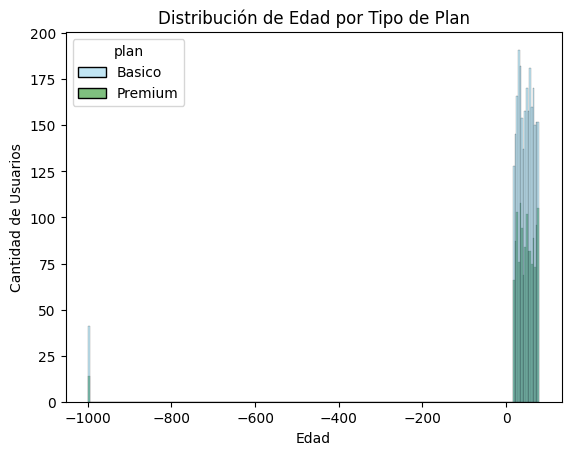

In [98]:
# Histograma para visualizar la edad (age

import pandas as pd

users = pd.read_csv("users_latam.csv")
usage = pd.read_csv("usage.csv")
plans = pd.read_csv("plans.csv")

user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile["age"].head(10)

sns.histplot(data=user_profile, x="age", hue="plan",
             palette=["skyblue", "green"], kde=False)
plt.title("Distribución de Edad por Tipo de Plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de Usuarios")
plt.show()



💡Insights: 

"Dentro del plan Premium, hay mayor proporción de en edades medias 30-45 anos "
"Los usuarios Básico tienden a ser mas dispersa  con mayor presencia de jovenes."
¿Qué tipo de distribución es ligeramente sesgada a la derecha indicando que hay mas usuarios jovenes que mayores. 


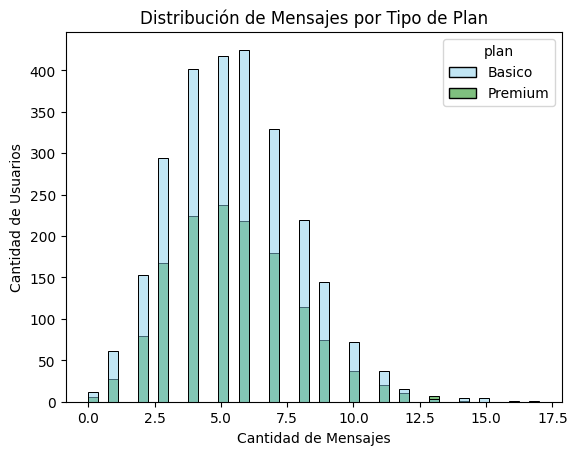

In [87]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan",
             palette=["skyblue", "green"], kde=False)
plt.title("Distribución de Mensajes por Tipo de Plan")
plt.xlabel("Cantidad de Mensajes")
plt.ylabel("Cantidad de Usuarios")
plt.show()



💡Insights: 

"Dentro del plan Premium, hay mayor proporción de tienden a enviar mas mensajes que el plan basico, especialmente en los rangos altos"
¿Qué tipo de distribución esta fuertemente sesgada a la derecha, lo que indica que la mayoria de usuarios envia pocos mensajes, pero existe un grupo pequeno que envia muchisimos. 


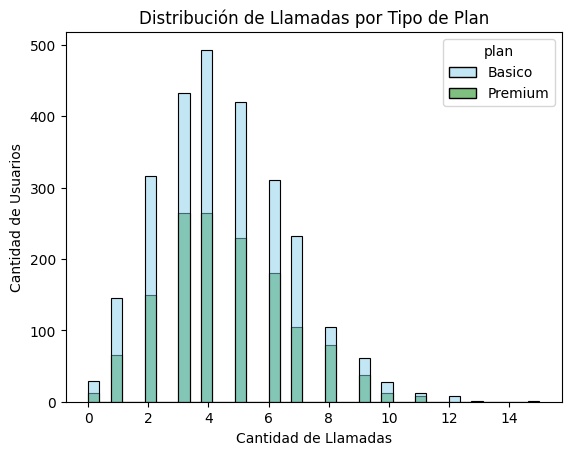

In [88]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data=user_profile, x="cant_llamadas", hue="plan",
             palette=["skyblue", "green"], kde=False)
plt.title("Distribución de Llamadas por Tipo de Plan")
plt.xlabel("Cantidad de Llamadas")
plt.ylabel("Cantidad de Usuarios")
plt.show()




💡Insights: 
"Dentro del plan Premium, hay mayor usuarios que realizan llamadas en promedio que los del plan basico, aunque ambos planes muestran una concentracion fuerte en valores bajos."
¿Qué tipo de distribución es sesgada a la derecha con muchos usuarios que hacen pocas llamadas y pocos usuarios que hacen muchisimas.


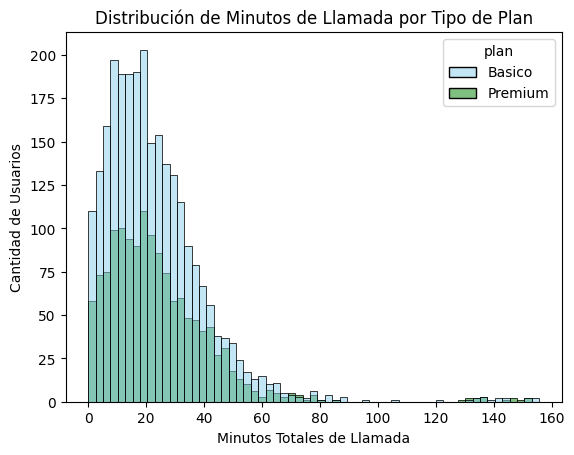

In [89]:
# Histograma para visualizar la cant_minutos_llamada

sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan",
             palette=["skyblue", "green"], kde=False)
plt.title("Distribución de Minutos de Llamada por Tipo de Plan")
plt.xlabel("Minutos Totales de Llamada")
plt.ylabel("Cantidad de Usuarios")
plt.show()


💡Insights: 

"Dentro del plan Premium se presenta una mayor proporcion de usuarios con altos minutos de llamada, esto indica un uso mas intensivo del servicio"
¿Qué tipo de distribución esta muy sesgada a la derecha indicando que la mayoria de ususarios habla poco, pero existe un grupo reducido con uso intensivo. 


### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

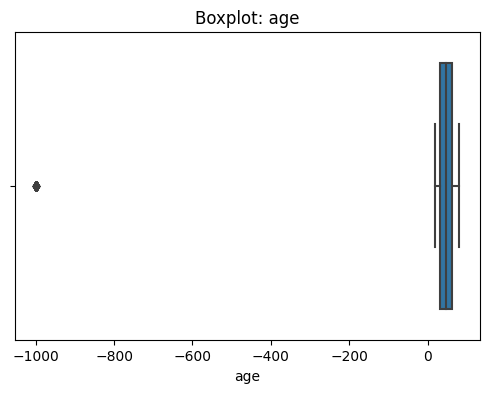

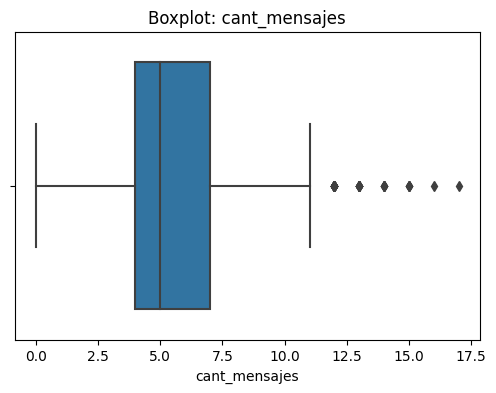

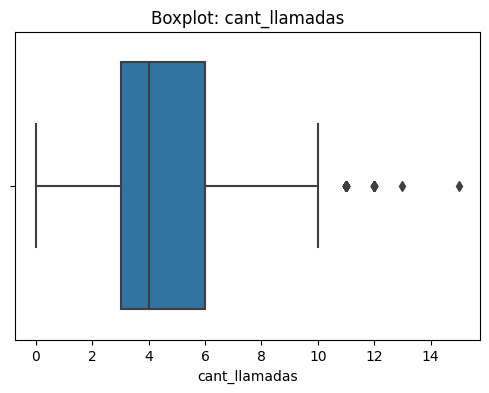

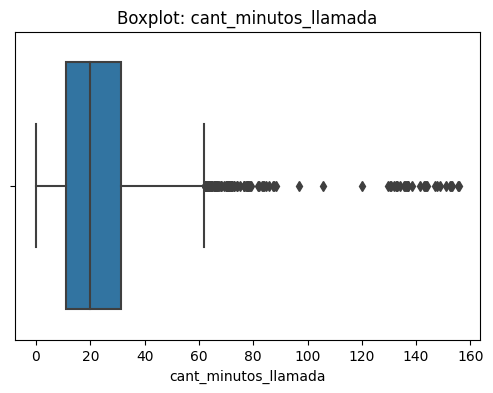

In [99]:

# Visualizando usando BoxPlot 

import matplotlib.pyplot as plt
import seaborn as sns

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()



💡Insights: 
- Age: presenta muy pocos outliers, los valores en su mayoria se concentran en un rango estable, adultos jovenes y medios, los valores extremos que aparecen en l aparte superio del boxplot, corresponden a usuarios mayores, pero son pocos y no afectan de manera significativa el analisis. 
- cant_mensajes: si presenta outliers claros, se pueden ver usuarios que envian una cantidad de mensajes muy superior al promedio, grupo reducido de heavy texters
- cant_llamadas: presenta outliers altos, algunos usuarios realizan un numero de llamadas muy por encima del resto, lo que en comun en perfiles de uso intensivo. 
- cant_minutos_llamada: Esta es la variable con mas outliers, hay usuarios que acumulas miles de minutos de llamada, generando una cola larga en el boxplot, representando asi el uso intensivo de este servicio. 

In [102]:

# Calcular límites con el método IQR
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\nColumna: {col}')
    print(f'Límite inferior: {limite_inferior}')
    print(f'Límite superior: {limite_superior}')

    outliers = user_profile[(user_profile[col] < limite_inferior) | (user_profile[col] > limite_superior)]
    print(f'Cantidad de outliers: {len(outliers)}')




Columna: age
Límite inferior: -14.5
Límite superior: 109.5
Cantidad de outliers: 55

Columna: cant_mensajes
Límite inferior: -0.5
Límite superior: 11.5
Cantidad de outliers: 46

Columna: cant_llamadas
Límite inferior: -1.5
Límite superior: 10.5
Cantidad de outliers: 30

Columna: cant_minutos_llamada
Límite inferior: -19.322500000000005
Límite superior: 61.8575
Cantidad de outliers: 109


In [103]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,33.739750,5.524381,4.478120,23.317054
std,123.232257,2.358416,2.144238,18.168095
min,-999.000000,0.000000,0.000000,0.000000
25%,32.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?, se mantienen los outliers ya que el limite superior en mucho menor que el valor maximo real y representan heavy users y son importantes para el analisis de consumo. 
- cant_llamadas: mantener o no outliers, porqué? el limite superior es menor que el maximo real se mantienen los outliers ya que reflejan el comportamiento real del negocio. 
- cant_minutos_llamada: mantener o no outliers, porqué? se mantiene los outliers porque el limite superior IQR es muy inferior al valor maximo real y aporten informacion valiosa sobre el uso intensivo del servicio y esto sirve para la segmentacio y analisis de clientes, 

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [105]:
# Crear columna grupo_uso
import numpy as np

user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),
        'Uso medio',
        'Alto uso'
    )
)



In [106]:
# verificar cambios
user_profile[['cant_llamadas', 'cant_mensajes', 'grupo_uso']].head(10)


,cant_llamadas,cant_mensajes,grupo_uso
0,3.0,7.0,Uso medio
1,10.0,5.0,Alto uso
2,2.0,5.0,Uso medio
3,3.0,11.0,Alto uso
4,3.0,4.0,Bajo uso
5,7.0,5.0,Uso medio
6,5.0,3.0,Uso medio
7,5.0,3.0,Uso medio
8,5.0,5.0,Uso medio
9,3.0,5.0,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [107]:
# Crear columna grupo_edad
import numpy as np

user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 
    'Joven',
    np.where(
        user_profile['age'] < 60,
        'Adulto',
        'Adulto Mayor'
    )
)


In [108]:
# verificar cambios
user_profile[['age', 'grupo_edad']].head(10)


,age,grupo_edad
0,38,Adulto
1,53,Adulto
2,57,Adulto
3,69,Adulto Mayor
4,63,Adulto Mayor
5,61,Adulto Mayor
6,39,Adulto
7,70,Adulto Mayor
8,76,Adulto Mayor
9,47,Adulto


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

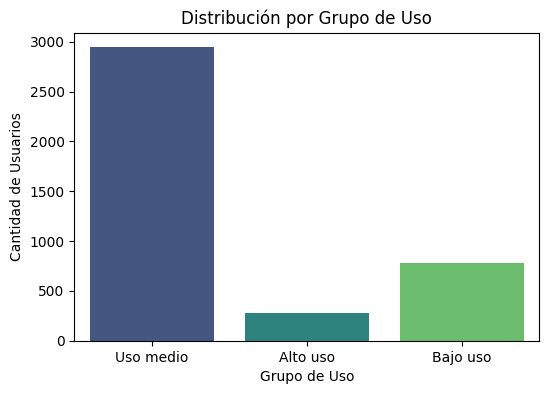

In [109]:
# Visualización de los segmentos por uso
plt.figure(figsize=(6,4))
sns.countplot(data=user_profile, x='grupo_uso', palette='viridis')
plt.title('Distribución por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()


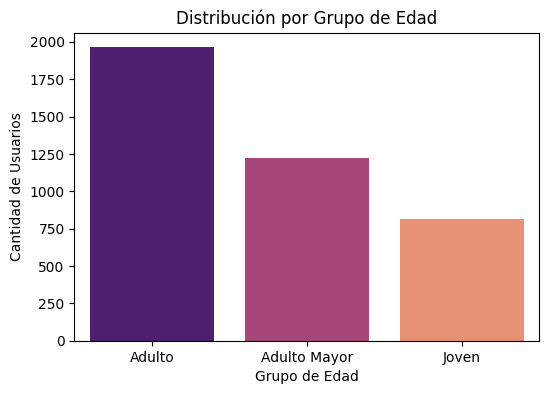

In [110]:
# Visualización de los segmentos por edad
plt.figure(figsize=(6,4))
sns.countplot(data=user_profile, x='grupo_edad', palette='magma')
plt.title('Distribución por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()



---
## 🧩Paso 7: 
Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- a. Valores faltantes en columnas clave, especialmente en age, debido a que el dataset original contenía registros incompletos o inconsistentes.
- b. Outliers extremos en variables de uso (cant_mensajes, cant_llamadas, cant_minutos_llamada), que inicialmente parecían errores pero representan comportamientos reales de clientes con uso intensivo.
- c.Filas con valores inválidos o no numéricos, que requerían limpieza para evitar distorsiones en los gráficos y métricas.

🔍 **Segmentos por Edad**
- a. Jóvenes (<30): uso moderado, sensibles al precio y a beneficios digitales.
- b. Adultos (30–59): mayor estabilidad, uso más alto y preferencia por planes completos.
- c. Adultos mayores (60+): menor uso, pero alta permanencia. 

📊 **Segmentos por Nivel de Uso**
se evidenciaron tres grupos:
- a. Bajo uso: usuarios con menos de 5 llamadas y menos de 5 mensajes, representan la mayor parte de la base, con uso ocasional del servicio.
- b. Uso medio: usuarios con menos de 10 llamadas y menos de 10 mensajes.
→presenta  estabilidad, con uso regular y potencial de crecimiento.
c. Alto uso: usuarios con más llamadas, más mensajes y más minutos.
es relativamente pequeño pero altamente valioso, responsable de gran parte del tráfico.

💡 **Recomendaciones**
1. Crear planes diferenciados por nivel de uso
Plan Básico: dirigido a Bajo Uso (llamadas y mensajes limitados).

Plan Plus: para Uso Medio (más minutos y mensajes).

Plan Premium: para Alto Uso (minutos ilimitados, beneficios adicionales).

2. Ofrecer beneficios digitales para atraer a Jóvenes
Redes sociales ilimitadas.

Paquetes de datos para streaming.

Promociones de upgrade temporal.

3. Diseñar un plan “Senior” para Adultos Mayores
Pocas llamadas, pocos mensajes, precio bajo.

Atención personalizada y soporte prioritario.

4. Crear campañas de retención para usuarios de Alto Uso
Bonos de minutos.

Descuentos por permanencia.

Programas de lealtad.

5. Monitorear continuamente los outliers
Detectar cambios en patrones de consumo.

Identificar clientes que podrían migrar a planes superiores.

Prevenir saturación de red en zonas de alto tráfico.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.




### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**. 
 

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`